# Fifth Practice

### Authors: Guillem Calvo Gallardo 23500820 and Oscar Romero López 21865336

###### [AI usage note: to be written]

###### [Division of the work: to be written]

In [28]:
# Necessary libraries
import numpy as np
import math
import matplotlib.pyplot as plt
import sys

# QPGC is only given compiled up to Python 3.9, so this notebook runs on a Python 3.9 environment
sys.path.insert(0, "compiled_code/Python3.9")
import QPGC

## 1. The dual problem as a quadratic problem

We want to solve the dual problem of the Support Vector Machine:

$$
\begin{aligned}
\text{maximize} \quad & f(\alpha) = \sum_{i=1}^{m}\alpha_{i} - \frac{1}{2}\alpha^{T}(YX^{T}XY)\alpha \\
\text{subject to} \quad & \sum_{i=1}^{m} y_{i}\alpha_{i} = 0 \\
& 0 \leq \alpha_{i} \leq K
\end{aligned}
$$

and the solver we have, `QPGC.QPGenericConstraints`, solves the problem:

$$
\begin{aligned}
\text{minimize} \quad & \frac{1}{2}x^{T}Gx + g^{T}x \\
\text{subject to} \quad & A^{T}x = b, \quad C^{T}x \geq d
\end{aligned}
$$

Maximizing $f(\alpha)$ is the same as minimizing $-f(\alpha) = \frac{1}{2}\alpha^{T}(YX^{T}XY)\alpha - \sum_{i=1}^{m}\alpha_{i}$, so with $x = \alpha \in \mathbb{R}^{m}$ we only have to identify each piece:

- $G = YX^{T}XY \in \mathbb{R}^{m \times m}$, that is $G_{ij} = y_{i}y_{j}\,x_{i}^{T}x_{j}$.
- $g = -(1, \dots, 1)^{T} \in \mathbb{R}^{m}$.
- $A = y \in \mathbb{R}^{m \times 1}$ and $b = 0 \in \mathbb{R}$, the only equality constraint $y^{T}\alpha = 0$.
- The box $0 \leq \alpha_{i} \leq K$ becomes two inequalities, $\alpha_{i} \geq 0$ and $-\alpha_{i} \geq -K$, so

$$
C^{T} = \begin{pmatrix} I \\ -I \end{pmatrix}, \quad C = \begin{pmatrix} I & -I \end{pmatrix} \in \mathbb{R}^{m \times 2m}, \qquad
d = \begin{pmatrix} 0 \\ \vdots \\ 0 \\ -K \\ \vdots \\ -K \end{pmatrix} \in \mathbb{R}^{2m}
$$

In the code we store the points as the rows of `X` (an $m \times 2$ matrix), so the $X$ of the statement is our `X.T` and $G$ is computed as `Y @ X @ X.T @ Y`. Notice that $G$ is a Gram matrix, so it is symmetric and semidefinite positive, but its rank is at most $2$ (the dimension of the points). So for $m > 2$ it is singular, and the problem is convex but not strictly convex.

Let's check how the solver has to be called:

In [29]:
help(QPGC.QPGenericConstraints)

Help on function QPGenericConstraints in module QPGC:

QPGenericConstraints(G, g, A, C, b, d)
    Convex optimization problem with equality and inequality constraints:
     
               min f(x)=1/2 x^T G X + g^T x     s.t.   A^T x = b i C^T x >= d
    
    Call it with:
    
    x = QPGenericConstrains(G, g, A, C, b, d)
    
    Notation:
    
    n = number of variables
    p = number of equality constants
    m = number of inequality constants
     
    Dimensions:   G -> n x n
                  g -> n x 1
                  A -> n x p
                  C -> n x m
                  b -> p x 1  
                  d -> m x 1



We also look at the constants used inside the compiled function. This will be useful to understand some of the results later on.

In [30]:
print(QPGC.QPGenericConstraints.__code__.co_consts[5:])
print(QPGC.QPGenericConstraints.__code__.co_varnames[7:])

(1, 100, 1e-05, 1e-16, ('axis',), 3, 0.95)
('n', 'p', 'm', 'itermax', 'x0', 'gam0', 'lamb0', 's0', 'Lamb', 'S', 'KKT', 'ev', 'rL', 'rA', 'rC', 'rslamb', 'mu', 'eps', 'nit', 'indep', 'incr', 'dx', 'dgam', 'dlamb', 'ds', 'alp', 'mu2', 'sigm', 'dS', 'dLamb')


From the names of the variables (`lamb0`, `s0`, `mu`, `sigm`, `KKT`, `Newton_step`...) we see that it is the primal-dual interior point method with predictor-corrector steps from the Numerical Linear Algebra course. From the constants: `itermax = 100`, the tolerance is `eps = 1e-05`, the starting point is `x0 = 1e-05 * np.random.rand(n)` and the multipliers and slacks start at $\lambda^{0} = s^{0} = (1, \dots, 1)^{T}$, and the step is shortened by $0.95$. It is important to keep in mind that **the solver stops after 100 iterations, even if it has not converged, and does not tell us**.

#### Recovering $w$ and $b$, and checking the solution

Once we have $\alpha$:

$$
w = \sum_{i=1}^{m}\alpha_{i}y_{i}x_{i}, \qquad b = \text{mean}\left\{ y_{j} - w^{T}x_{j} \;:\; 0 < \alpha_{j} < K \right\}
$$

Numerically $\alpha_{i}$ never is exactly $0$ or $K$, so we say $\alpha_{i} = 0$ if $\alpha_{i} < 10^{-6}K$ and $\alpha_{i} = K$ if $\alpha_{i} > (1 - 10^{-6})K$.

Since the solver does not tell us if it has converged, we need a way to check it. We use the **duality gap**. For any $\alpha$ feasible for the dual and any $(w, b, \xi)$ feasible for the primal (7), weak duality says that

$$
P(w, \xi) = \frac{1}{2}w^{T}w + K\sum_{i=1}^{m}\xi_{i} \;\geq\; f(\alpha)
$$

and at the optimum both values are equal. Given $w$ and $b$, the smallest feasible $\xi_{i}$ is $\xi_{i} = \max\left(0, 1 - y_{i}(w^{T}x_{i} + b)\right)$. So we compute the relative gap $\frac{P - f}{|P|}$: if it is close to $0$ the solution is optimal, if not, the solver has not converged.

In [31]:
def svm_dual(X, y, K, tol=1e-6):
    m = len(y)
    Y = np.diag(y)
    G = Y @ X @ X.T @ Y
    g = -np.ones(m)
    A = y.reshape(m, 1)
    b = np.zeros(1)
    C = np.hstack([np.eye(m), -np.eye(m)])
    d = np.concatenate([np.zeros(m), -K * np.ones(m)])

    try:
        alpha = np.array(QPGC.QPGenericConstraints(G, g, A, C, b, d)).ravel()
    except np.linalg.LinAlgError as e:
        # The KKT matrix of the interior point method has become singular
        return {"K": K, "status": str(e)}

    w = X.T @ (alpha * y)
    zero = alpha < tol * K
    bound = alpha > (1 - tol) * K
    sv = ~zero & ~bound
    b = np.mean(y[sv] - X[sv] @ w) if sv.any() else np.nan

    # Duality gap
    xi = np.maximum(0, 1 - y * (X @ w + b))
    primal = 0.5 * w @ w + K * np.sum(xi)
    dual = np.sum(alpha) - 0.5 * alpha @ G @ alpha
    gap = (primal - dual) / abs(primal)

    return {"K": K, "status": "ok", "alpha": alpha, "w": w, "b": b, "zero": zero, "sv": sv, "bound": bound,
            "margin": 2 / np.linalg.norm(w), "acc": np.mean(np.sign(X @ w + b) == y), "gap": gap, "sum_ya": y @ alpha}

To plot the results we draw the level lines $f(x) = w^{T}x + b = 0$ (solid) and $f(x) = \pm 1$ (dashed). The points with $0 < \alpha_{i} < K$ (support vectors) are circled in black and the ones with $\alpha_{i} = K$ are marked with a black square, as in Figure 2 of the statement.

In [32]:
def generate_data(m2, n, seed):
    m1 = [0., 0.]
    s1 = [[1, -0.9], [-0.9, 1]]
    s2 = [[1, 0], [0, 1]]
    np.random.seed(seed)
    X = np.vstack([np.random.multivariate_normal(m1, s1, n), np.random.multivariate_normal(m2, s2, n)])
    y = np.concatenate([np.ones(n), -np.ones(n)])
    return X, y

def plot_svm(ax, X, y, r, title):
    ax.scatter(X[y == 1, 0], X[y == 1, 1], color="blue", s=15, alpha=0.7, label="y = +1")
    ax.scatter(X[y == -1, 0], X[y == -1, 1], color="red", s=15, alpha=0.7, label="y = -1")
    xlim, ylim = ax.get_xlim(), ax.get_ylim()
    if r["status"] == "ok" and np.all(np.isfinite(r["w"])) and np.isfinite(r["b"]):
        ax.scatter(X[r["sv"], 0], X[r["sv"], 1], s=120, facecolors="none", edgecolors="black", lw=1.5, label="0 < α < K")
        ax.scatter(X[r["bound"], 0], X[r["bound"], 1], s=90, marker="s", facecolors="none", edgecolors="black", lw=1.2, label="α = K")
        xx, yy = np.meshgrid(np.linspace(*xlim, 300), np.linspace(*ylim, 300))
        ff = r["w"][0] * xx + r["w"][1] * yy + r["b"]
        ax.contour(xx, yy, ff, levels=[-1, 0, 1], colors=["red", "black", "blue"], linestyles=["--", "-", "--"])
    else:
        ax.text(0.5, 0.5, "No valid solution", transform=ax.transAxes, ha="center", fontsize=14)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
    ax.set_title(title)

def print_summary(results, extra_name=None):
    head = f"{extra_name:>8} | " if extra_name else ""
    print(head + f"{'K':>7} | {'w1':>10} | {'w2':>10} | {'b':>10} | {'α=0':>4} | {'0<α<K':>5} | {'α=K':>4} | {'Margin':>8} | {'Acc':>6} | {'Gap':>9}")
    print("-" * (len(head) + 103))
    for extra, r in results:
        head = f"{extra:>8} | " if extra_name else ""
        if r["status"] != "ok":
            print(head + f"{r['K']:>7g} | {r['status']}")
            continue
        print(head + f"{r['K']:>7g} | {r['w'][0]:>10.4g} | {r['w'][1]:>10.4g} | {r['b']:>10.4g} | {r['zero'].sum():>4} | {r['sv'].sum():>5} | {r['bound'].sum():>4} | {r['margin']:>8.4g} | {r['acc']:>6.3f} | {r['gap']:>9.2e}")

## 2. Separable dataset

We use $m_{1} = (0, 0)$, $s_{1} = \begin{pmatrix} 1 & -0.9 \\ -0.9 & 1 \end{pmatrix}$ for the class $y = +1$ and $m_{2} = (3, 6)$, $s_{2} = I$ for the class $y = -1$.

### 2.1 Two points per class, $K = 1$

We start with the simplest case.

w = [-0.15033738 -0.26992129], b = 0.9539, margin = 6.4732, gap = 1.85e-07, y^T α = -4.9e-17

Point |       x1 |       x2 |   y |          α |   y·f(x)
-------------------------------------------------------
    0 |   0.9371 |  -0.8120 |  +1 |  8.875e-08 |   1.0322
    1 |   0.6851 |  -0.5524 |  +1 |  4.773e-02 |   1.0000
    2 |   3.8348 |   5.1029 |  -1 |  4.773e-02 |   1.0000
    3 |   2.0970 |   6.3325 |  -1 |  5.113e-08 |   1.0707


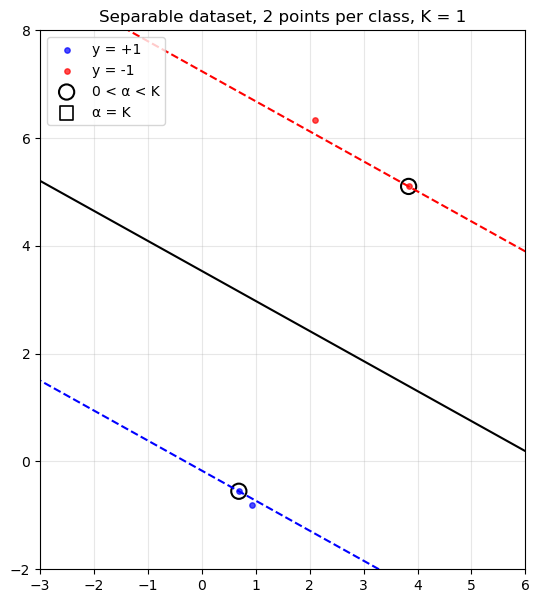

In [33]:
sep_m2 = [3., 6.]
X_small, y_small = generate_data(sep_m2, 2, 112358)
r_small = svm_dual(X_small, y_small, K=1)

f_small = X_small @ r_small["w"] + r_small["b"]
print(f"w = {r_small['w']}, b = {r_small['b']:.4f}, margin = {r_small['margin']:.4f}, gap = {r_small['gap']:.2e}, y^T α = {r_small['sum_ya']:.1e}\n")
print(f"{'Point':>5} | {'x1':>8} | {'x2':>8} | {'y':>3} | {'α':>10} | {'y·f(x)':>8}")
print("-" * 55)
for i in range(len(y_small)):
    print(f"{i:>5} | {X_small[i, 0]:>8.4f} | {X_small[i, 1]:>8.4f} | {y_small[i]:>+3.0f} | {r_small['alpha'][i]:>10.3e} | {y_small[i] * f_small[i]:>8.4f}")

fig, ax = plt.subplots(figsize=(7, 7))
ax.set_xlim(-3, 6)
ax.set_ylim(-2, 8)
plot_svm(ax, X_small, y_small, r_small, "Separable dataset, 2 points per class, K = 1")
ax.legend(loc="upper left")
plt.show()

The hyperplane separates both classes, and the dashed lines $f(x) = \pm 1$ touch exactly the two circled points, the support vectors (points 1 and 2), which have $y_{i}f(x_{i}) = 1.0000$. The other two points have $\alpha_{i} \approx 10^{-8}$, which is numerically $0$, and $y_{i}f(x_{i}) > 1$, so they are outside the margin and do not contribute to $w$.

Both support vectors have the same $\alpha = 0.0477$. This is not a coincidence: there is one support vector per class, so the equality constraint $\sum y_{i}\alpha_{i} = 0$ forces $\alpha_{1} - \alpha_{2} = 0$ (and we get $y^{T}\alpha \approx 10^{-17}$, so the constraint is satisfied). The relative duality gap is $1.85 \cdot 10^{-7}$, so the solver has converged to the optimum.

Notice also that $\max \alpha_{i} = 0.0477 < K = 1$, so the upper bound $\alpha_{i} \leq K$ is not active: what we have obtained is the solution of the separable problem (6), with no upper bound.

### 2.2 One hundred points per class, $K = 1$

      K |         w1 |         w2 |          b |  α=0 | 0<α<K |  α=K |   Margin |    Acc |       Gap
-------------------------------------------------------------------------------------------------------
      1 |    -0.3328 |    -0.4817 |      1.567 |  197 |     3 |    0 |    3.416 |  1.000 |  6.35e-08

min y·f(x) = 1.0000
y·f(x) of the support vectors: [1. 1. 1.]
α of the support vectors:      [0.1714 0.0029 0.1685]
largest α of the rest:         3.09e-10


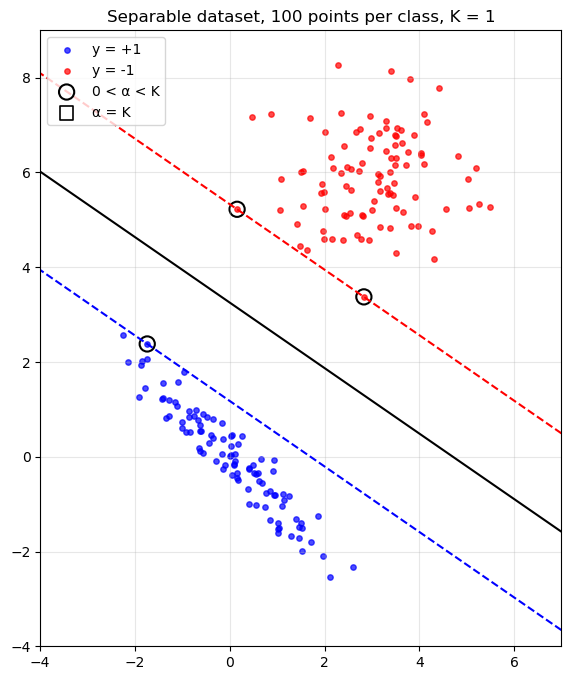

In [34]:
X_sep, y_sep = generate_data(sep_m2, 100, 112358)
r_sep = svm_dual(X_sep, y_sep, K=1)

print_summary([(None, r_sep)])
f_sep = X_sep @ r_sep["w"] + r_sep["b"]
print(f"\nmin y·f(x) = {np.min(y_sep * f_sep):.4f}")
print(f"y·f(x) of the support vectors: {np.round(y_sep[r_sep['sv']] * f_sep[r_sep['sv']], 4)}")
print(f"α of the support vectors:      {np.round(r_sep['alpha'][r_sep['sv']], 4)}")
print(f"largest α of the rest:         {np.max(r_sep['alpha'][~r_sep['sv']]):.2e}")

fig, ax = plt.subplots(figsize=(8, 8))
ax.set_xlim(-4, 7)
ax.set_ylim(-4, 9)
plot_svm(ax, X_sep, y_sep, r_sep, "Separable dataset, 100 points per class, K = 1")
ax.legend(loc="upper left")
plt.show()

With $200$ points the hyperplane still separates correctly both classes (accuracy $1.000$) and the duality gap is $6.35 \cdot 10^{-8}$. Only $3$ of the $200$ points are support vectors, one of the class $+1$ ($\alpha = 0.1714$) and two of the class $-1$ ($\alpha = 0.0029$ and $0.1685$); again $0.1714 - 0.0029 - 0.1685 = 0$. These three points have $y_{i}f(x_{i}) = 1$, so the dashed lines touch them, and $\min y_{i}f(x_{i}) = 1$, meaning that no point is inside the margin. The remaining $197$ points have $\alpha_{i} \leq 3.09 \cdot 10^{-10}$.

This shows the main property of the SVM: the hyperplane is $w = \sum \alpha_{i}y_{i}x_{i}$, so it only depends on the $3$ support vectors. We could remove the other $197$ points and we would obtain exactly the same hyperplane. The margin is $2/\|w\| = 3.416$.

As before, $\max \alpha_{i} = 0.171 < K = 1$, so the bound $\alpha_{i} \leq K$ is not active.

### 2.3 Influence of $K$ in the separable case

We now solve the same problem with $K = 1, 10, 100, 10^{6}$ and $10^{12}$, and we repeat the experiment with three different random datasets (seeds).

In [35]:
K_values = [1, 5, 10, 20, 30, 40, 50]
seeds = [112358, 314159, 271828]

results_sep = {}
for seed in seeds:
    X, y = generate_data(sep_m2, 100, seed)
    for K in K_values:
        results_sep[(seed, K)] = svm_dual(X, y, K)

print_summary([(seed, results_sep[(seed, K)]) for seed in seeds for K in K_values], extra_name="Seed")

    Seed |       K |         w1 |         w2 |          b |  α=0 | 0<α<K |  α=K |   Margin |    Acc |       Gap
------------------------------------------------------------------------------------------------------------------
  112358 |       1 |    -0.3328 |    -0.4817 |      1.567 |  197 |     3 |    0 |    3.416 |  1.000 |  6.35e-08
  112358 |       5 |    -0.3328 |    -0.4816 |      1.567 |  197 |     3 |    0 |    3.416 |  1.000 |  1.89e-04
  112358 |      10 |    -0.3328 |    -0.4816 |      1.567 |  197 |     3 |    0 |    3.416 |  1.000 |  5.67e-03
  112358 |      20 |    -0.3329 |    -0.4816 |      1.567 |  197 |     3 |    0 |    3.416 |  1.000 |  1.92e-02
  112358 |      30 |    -0.3719 |    -0.4674 |      1.935 |    0 |   200 |    0 |    3.348 |  1.000 |  9.98e-01
  112358 |      40 |    -0.3437 |    -0.4794 |      1.885 |    4 |   196 |    0 |    3.391 |  1.000 |  9.97e-01
  112358 |      50 |     -1.333 |     -2.465 |      9.258 |    0 |   200 |    0 |   0.7138 |  1.000 |

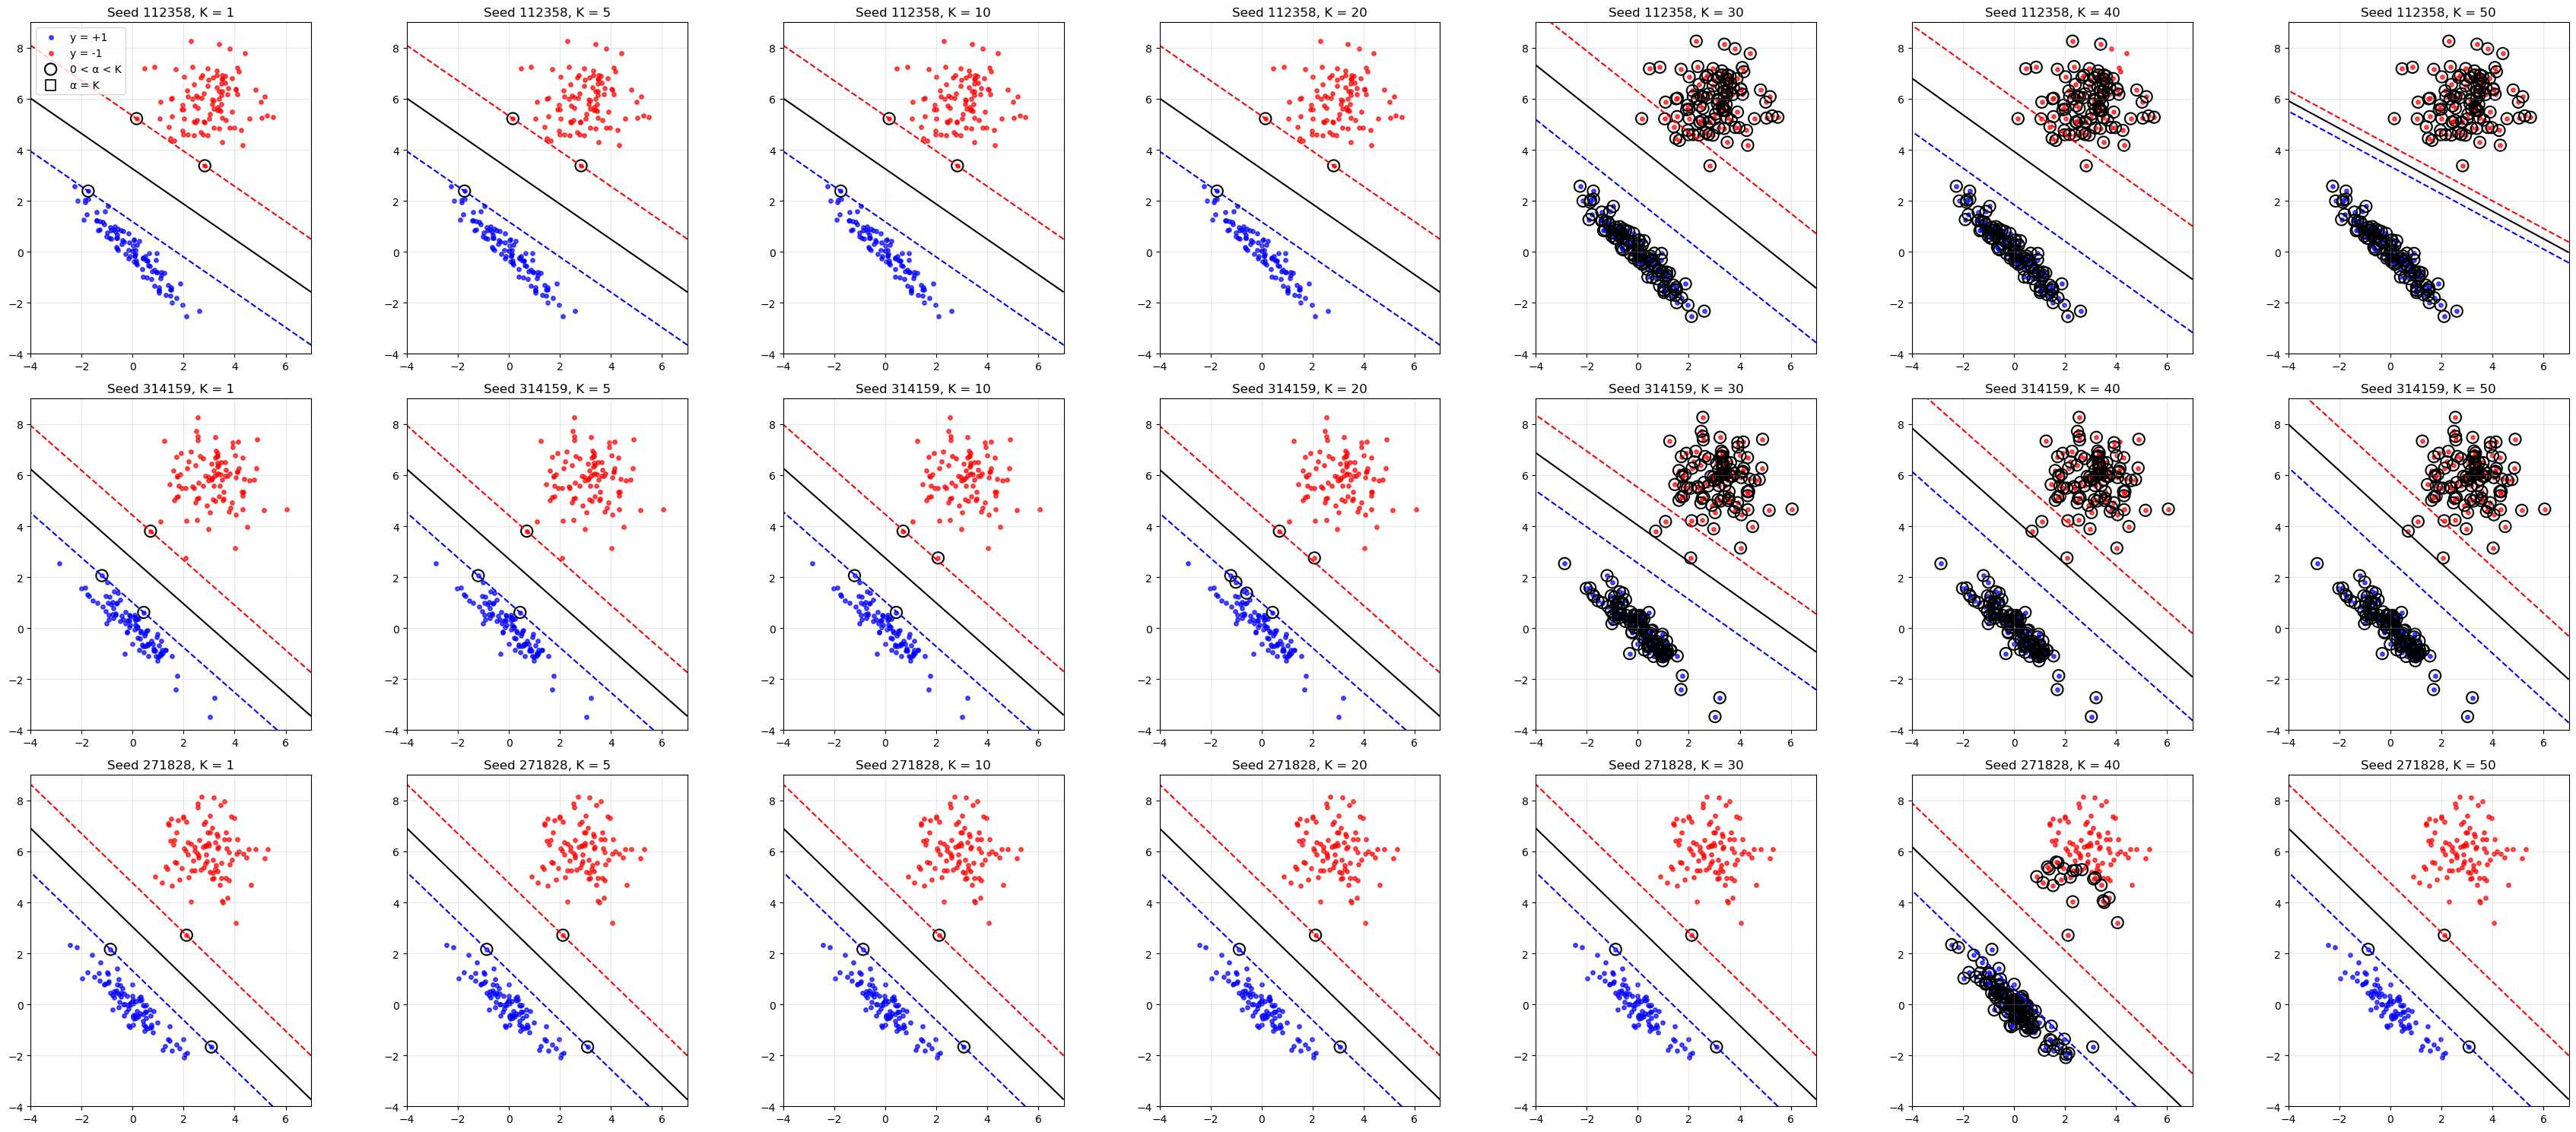

In [36]:
fig, axs = plt.subplots(len(seeds), len(K_values), figsize=(5 * len(K_values), 5 * len(seeds)))
for i, seed in enumerate(seeds):
    X, y = generate_data(sep_m2, 100, seed)
    for j, K in enumerate(K_values):
        axs[i, j].set_xlim(-4, 7)
        axs[i, j].set_ylim(-4, 9)
        plot_svm(axs[i, j], X, y, results_sep[(seed, K)], f"Seed {seed}, K = {K:g}")
axs[0, 0].legend(loc="upper left")
plt.tight_layout()
plt.show()

#### What should happen

In the separable case the solution of (6) has $\max \alpha_{i}^{*} = 0.171$ (seed 112358). For any $K \geq 0.171$ the constraint $\alpha_{i} \leq K$ is not active at the optimum, so the problem with the box has exactly the same solution as the problem (6) without upper bound. In exact arithmetic, **the value of $K$ should not influence the solution at all** for $K = 1, 10, 100, 10^{6}$ or $10^{12}$.

#### What we obtain

- $K = 1$ and $K = 10$: for the three seeds we obtain the same $w$, $b$, $3$ support vectors and margin. The hyperplane separates correctly all the points. However the duality gap already grows from $10^{-11}$-$10^{-7}$ with $K = 1$ to $10^{-5}$-$10^{-4}$ with $K = 10$.
- $K = 100$: for seeds 314159 and 271828 we still get the same solution, but with gaps of $2.3 \cdot 10^{-2}$ and $3.3 \cdot 10^{-3}$. For seed 112358 the solver does not converge (gap $1.00$): all $200$ points have $0 < \alpha_{i} < K$, so we can not distinguish the support vectors, and $b$, computed as the mean over all of them, becomes $2.042$ instead of $1.567$. The line still separates the points (the plot looks reasonable), but only because both classes are far apart, it is not the maximum margin hyperplane.
- $K = 10^{6}$ and $K = 10^{12}$: the results are meaningless. $w$ has components of order $10^{4}$ to $10^{24}$, the "margin" is of order $10^{-5}$ to $10^{-24}$, and we get accuracies of $0.000$ (the orientation of $w$ is flipped, every point is on the wrong side), $0.49$ or $0.78$. In two cases no $\alpha_{i}$ is strictly between $0$ and $K$, so $b$ can not even be computed (`nan`).

So, does $K$ influence the solution? **Mathematically no, numerically yes.**

#### Why

$K$ only appears in the vector $d$, in the constraints $-\alpha_{i} \geq -K$. The solver starts at $\alpha^{0} \approx 0$ with slacks $s^{0} = 1$, so the residual of these constraints at the start, $-\alpha_{i} - s_{i} + K$, is of order $K$. The method stops when the residuals are below $10^{-5}$, so it has to reduce them by a factor $K / 10^{-5}$: $10^{6}$ for $K = 1$, but $10^{11}$ for $K = 10^{6}$ and $10^{17}$ for $K = 10^{12}$, and it only has $100$ iterations to do so. When it does not reach the tolerance it just returns the last iterate.

Moreover, at the optimum the slacks of the upper bounds are $s_{i} = K - \alpha_{i} \approx K$, whilst the slacks of the lower bounds of the non support vectors tend to $0$. The matrices $S$ and $\Lambda$ are blocks of the KKT matrix that is solved at each Newton step, so this matrix has entries from $\sim 10^{-10}$ to $\sim K$. Its condition number grows with $K$, and with $K = 10^{12}$ it is far beyond $1/\varepsilon_{\text{machine}} \approx 10^{16}$: the linear systems are solved with no correct digits (and in section 3 `numpy` even reports the matrix as singular).

Recall that the separable problem (6) has no upper threshold for $\alpha$, so one could think that the best is to take $K$ as large as possible to "imitate" $K = \infty$. The experiments show the opposite: the best $K$ is a moderate one, large enough so that the bound is not active ($K \geq \max \alpha_{i}^{*}$), but not so large that the interior point method becomes ill-conditioned.

Since the solver starts from a random point, we also repeat several times the solve of the **same** dataset (seed 112358) to see if the result changes.

In [37]:
X_sep, y_sep = generate_data(sep_m2, 100, 112358)
n_rep = 5

results_rep_sep = []
for K in K_values:
    for rep in range(n_rep):
        results_rep_sep.append((rep, svm_dual(X_sep, y_sep, K)))

print_summary(results_rep_sep, extra_name="Repeat")

  Repeat |       K |         w1 |         w2 |          b |  α=0 | 0<α<K |  α=K |   Margin |    Acc |       Gap
------------------------------------------------------------------------------------------------------------------
       0 |       1 |    -0.3328 |    -0.4817 |      1.567 |  197 |     3 |    0 |    3.416 |  1.000 |  6.35e-08
       1 |       1 |    -0.3328 |    -0.4817 |      1.567 |  197 |     3 |    0 |    3.416 |  1.000 |  3.18e-09
       2 |       1 |    -0.3328 |    -0.4817 |      1.567 |  197 |     3 |    0 |    3.416 |  1.000 |  3.18e-09
       3 |       1 |    -0.3328 |    -0.4817 |      1.567 |  197 |     3 |    0 |    3.416 |  1.000 |  3.18e-09
       4 |       1 |    -0.3328 |    -0.4817 |      1.567 |  197 |     3 |    0 |    3.416 |  1.000 |  1.27e-06
       0 |       5 |    -0.3328 |    -0.4817 |      1.567 |  197 |     3 |    0 |    3.416 |  1.000 |  9.46e-06
       1 |       5 |    -0.3328 |    -0.4816 |      1.567 |  197 |     3 |    0 |    3.416 |  1.000 |

With the same dataset, the only thing that changes between repetitions is the starting point $\alpha^{0} = 10^{-5} \cdot \text{rand}(m)$, a perturbation of order $10^{-5}$.

- $K = 1$: the five repetitions give exactly the same solution, with gaps between $10^{-9}$ and $10^{-6}$.
- $K = 10$: the same $w$ and $b$ in all of them, but the gap is now $10^{-4}$-$10^{-3}$.
- $K = 100$: only repetition 0 gets close to the solution (gap $0.17$). Three repetitions return the non converged solution we saw before ($b = 2.042$) and repetition 3 returns $w = (-1.053, -1.995)$, with a margin of $0.89$ instead of $3.42$.
- $K = 10^{6}$ and $10^{12}$: every repetition gives a different, wrong solution, with accuracies from $0.00$ to $1.00$.

For small $K$ the solution is stable: it does not depend on the starting point, as it should for a convex problem. For large $K$ a perturbation of $10^{-5}$ in the starting point completely changes the result, which confirms that the problem is the numerical instability of the method and not the problem itself.

## 3. Non-separable dataset

Now $m_{2} = (1, 2)$, so both classes overlap, and we repeat the experiments with the same values of $K$ and the same seeds.

In [38]:
nonsep_m2 = [1., 2.]

results_nonsep = {}
for seed in seeds:
    X, y = generate_data(nonsep_m2, 100, seed)
    for K in K_values:
        results_nonsep[(seed, K)] = svm_dual(X, y, K)

print_summary([(seed, results_nonsep[(seed, K)]) for seed in seeds for K in K_values], extra_name="Seed")

    Seed |       K |         w1 |         w2 |          b |  α=0 | 0<α<K |  α=K |   Margin |    Acc |       Gap
------------------------------------------------------------------------------------------------------------------
  112358 |       1 |     -1.662 |     -1.747 |       1.61 |  164 |     3 |   33 |   0.8293 |  0.950 | -4.42e-16
  112358 |       5 |     -1.749 |     -1.808 |       1.69 |  168 |     3 |   29 |   0.7951 |  0.950 | -2.87e-15
  112358 |      10 |     -2.008 |     -2.076 |      1.788 |  167 |     8 |   25 |   0.6925 |  0.950 |  2.88e-04
  112358 |      20 |     -2.109 |     -2.244 |      3.183 |    0 |   200 |    0 |   0.6494 |  0.925 |  4.13e-01
  112358 |      30 |       -2.1 |     -2.234 |      1.958 |  170 |     3 |   27 |   0.6522 |  0.945 |  4.82e-15
  112358 |      40 |      -2.14 |       -2.3 |      3.251 |    0 |   200 |    0 |   0.6366 |  0.925 |  4.31e-01
  112358 |      50 |     -2.293 |     -2.465 |      3.484 |    0 |   200 |    0 |   0.5941 |  0.925 |

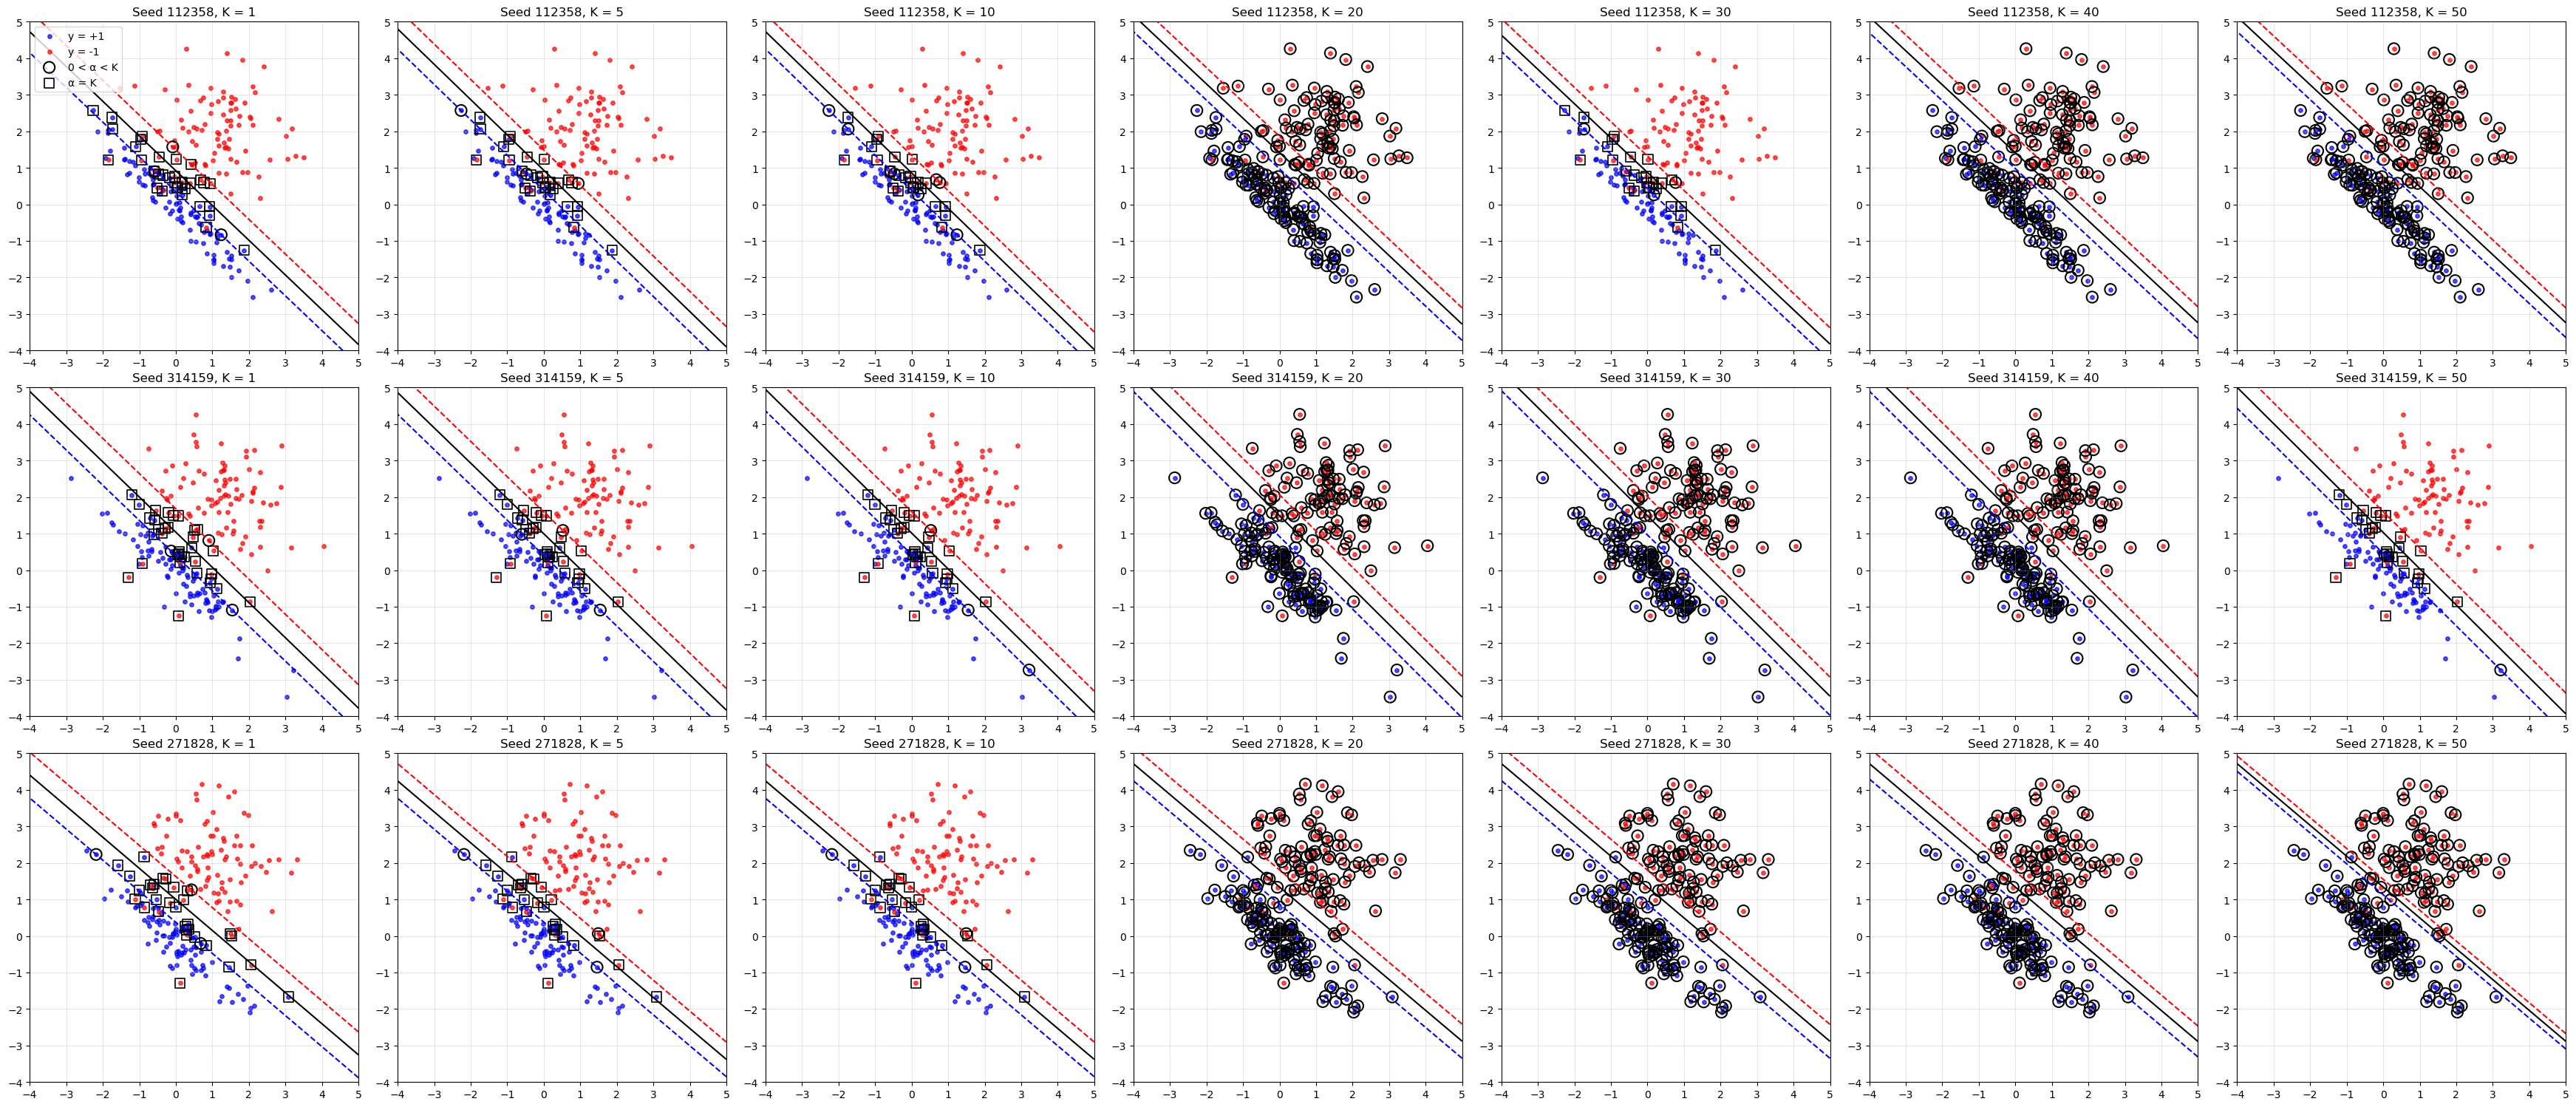

In [39]:
fig, axs = plt.subplots(len(seeds), len(K_values), figsize=(5 * len(K_values), 5 * len(seeds)))
for i, seed in enumerate(seeds):
    X, y = generate_data(nonsep_m2, 100, seed)
    for j, K in enumerate(K_values):
        axs[i, j].set_xlim(-4, 5)
        axs[i, j].set_ylim(-4, 5)
        plot_svm(axs[i, j], X, y, results_nonsep[(seed, K)], f"Seed {seed}, K = {K:g}")
axs[0, 0].legend(loc="upper left")
plt.tight_layout()
plt.show()

#### What should happen

Now there is no hyperplane that separates both classes, so some points must have $\xi_{i} > 0$ and the problem (6) has no solution: the primal (1) is infeasible, and its dual (6) is unbounded. Only the box $\alpha_{i} \leq K$ keeps the dual bounded, so here the upper bound is active and **$K$ does change the solution**. $K$ is the price we pay for each unit of violation $\xi_{i}$: a small $K$ allows violations in exchange of a wider margin, a large $K$ penalises them and gives a narrower margin.

#### What we obtain

Taking only the runs that have converged (gap below $10^{-9}$):

| Seed | $K$ | Margin | $\alpha = K$ | Accuracy |
|---|---|---|---|---|
| 112358 | 1 | 0.829 | 33 | 0.950 |
| 112358 | 10 | 0.693 | 28 | 0.950 |
| 314159 | 1 | 0.924 | 35 | 0.955 |
| 314159 | 10 | 0.838 | 32 | 0.950 |
| 314159 | 100 | 0.777 | 30 | 0.950 |
| 271828 | 1 | 0.955 | 31 | 0.950 |
| 271828 | 10 | 0.724 | 28 | 0.945 |
| 271828 | 100 | 0.708 | 26 | 0.945 |

As expected, when $K$ grows the margin decreases and there are fewer points with $\alpha_{i} = K$ (fewer points violating the margin). The accuracy, though, does not improve, it stays at about $95\%$: the classes overlap, so around $10$ points are on the wrong side of any line, and the different $K$ only move the line slightly.

For seed 271828, $K = 100$ and $K = 10^{6}$ give the same $w = (-1.823, -2.160)$. When $K \to \infty$ the term $K\sum \xi_{i}$ dominates the objective, and the solution tends to the hyperplane that minimizes $\sum \xi_{i}$, so $w$ stops changing. But the $\alpha_{i}$ of the points that violate the margin are equal to $K$, so they grow without limit, as the unbounded dual (6) suggests.

The numerical problems are the same as in the separable case, and worse: with $K = 100$ seed 112358 does not converge (gap $0.85$, all points as support vectors), with $K = 10^{6}$ only seed 271828 converges, and with $K = 10^{12}$ we never get a valid solution: seed 112358 raises `Singular matrix` and the other two give `nan`.

The statement says that the points with $\alpha_{j} = K$ are misclassified. We check it for $K = 1$, where all the runs have converged:

In [40]:
print(f"{'Seed':>8} | {'α=K':>4} | {'Misclassified (y·f < 0)':>23} | {'Inside margin (0 ≤ y·f < 1)':>27} | {'Total misclassified':>19}")
print("-" * 95)
for seed in seeds:
    X, y = generate_data(nonsep_m2, 100, seed)
    r = results_nonsep[(seed, 1)]
    yf = y * (X @ r["w"] + r["b"])
    yf_bound = yf[r["bound"]]
    print(f"{seed:>8} | {r['bound'].sum():>4} | {np.sum(yf_bound < 0):>23} | {np.sum((yf_bound >= 0) & (yf_bound < 1)):>27} | {np.sum(yf < 0):>19}")

    Seed |  α=K | Misclassified (y·f < 0) | Inside margin (0 ≤ y·f < 1) | Total misclassified
-----------------------------------------------------------------------------------------------
  112358 |   33 |                      10 |                          23 |                  10
  314159 |   35 |                       9 |                          26 |                   9
  271828 |   31 |                      10 |                          21 |                  10


Not all the points with $\alpha_{j} = K$ are misclassified: for seed 112358 only $10$ of the $33$ are, the other $23$ are correctly classified but inside the margin. What $\alpha_{j} = K$ really means is $\xi_{j} > 0$, that the point violates the margin $y_{j}f(x_{j}) \geq 1$. The converse does hold: all the misclassified points have $\alpha_{j} = K$ (the last column coincides with the number of misclassified points with $\alpha = K$).

In [41]:
X_nonsep, y_nonsep = generate_data(nonsep_m2, 100, 112358)

results_rep_nonsep = []
for K in K_values:
    for rep in range(n_rep):
        results_rep_nonsep.append((rep, svm_dual(X_nonsep, y_nonsep, K)))

print_summary(results_rep_nonsep, extra_name="Repeat")

  Repeat |       K |         w1 |         w2 |          b |  α=0 | 0<α<K |  α=K |   Margin |    Acc |       Gap
------------------------------------------------------------------------------------------------------------------
       0 |       1 |     -1.662 |     -1.747 |       1.61 |  164 |     3 |   33 |   0.8293 |  0.950 | -4.42e-16
       1 |       1 |     -1.662 |     -1.747 |       1.61 |  164 |     3 |   33 |   0.8293 |  0.950 |  2.03e-12
       2 |       1 |     -1.662 |     -1.747 |       1.61 |  164 |     3 |   33 |   0.8293 |  0.950 |  2.03e-12
       3 |       1 |     -1.662 |     -1.747 |       1.61 |  164 |     3 |   33 |   0.8293 |  0.950 | -4.42e-16
       4 |       1 |     -1.662 |     -1.747 |       1.61 |  164 |     3 |   33 |   0.8293 |  0.950 |  0.00e+00
       0 |       5 |     -1.749 |     -1.808 |       1.69 |  168 |     3 |   29 |   0.7951 |  0.950 | -2.29e-15
       1 |       5 |     -1.749 |     -1.808 |      1.646 |  165 |    10 |   25 |   0.7951 |  0.950 |

Repeating the solve on the same dataset:

- $K = 1$: the five repetitions give the same solution.
- $K = 10$: the five repetitions give the same $w = (-2.008, -2.076)$, but in two of them the gap is $0.15$ and $132$ points appear as support vectors, so $b = 1.276$ instead of $1.792$. Here $w$ had already converged, but the $\alpha_{i}$ had not yet separated into $0$, $(0, K)$ and $K$, and $b$, computed from the wrongly identified support vectors, is wrong.
- $K = 100$: repetition 0 converges (gap $1.9 \cdot 10^{-8}$, margin $0.652$), whilst the other four do not, and give margins from $0.13$ to $0.64$. Whether we obtain the correct solution depends on the starting point.
- $K = 10^{6}$ and $10^{12}$: wrong solutions or `Singular matrix` in every repetition.

## 4. Conclusions

- The dual SVM problem is a quadratic problem with one equality constraint and box constraints, so it can be solved with the interior point method `QPGenericConstraints` writing $0 \leq \alpha_{i} \leq K$ as $C^{T}\alpha \geq d$ with $C = (I \;\; -I)$.
- With a moderate $K$ (e.g. $K = 1$) the method converges, the hyperplane separates the points and the lines $f(x) = \pm 1$ touch the support vectors. The hyperplane is determined by very few points ($3$ of $200$ in the separable case).
- In the separable case $K$ should not affect the solution as long as $K \geq \max \alpha_{i}^{*}$. In practice large values of $K$ ($\geq 100$ in some datasets, always for $10^{6}$ and $10^{12}$) destroy the solution: the initial residuals are of order $K$, the 100 iterations of the solver are not enough, and the KKT systems become ill-conditioned. The results then depend on the random starting point.
- In the non-separable case $K$ is a real parameter of the model: it controls the trade-off between the width of the margin and the violations. Increasing $K$ narrows the margin and reduces the number of points with $\alpha_{i} = K$, but does not improve the accuracy. Large $K$ has the same numerical problems, even more severe.
- The points with $\alpha_{i} = K$ are the ones that violate the margin; they include the misclassified points but also correctly classified points inside the margin.
- Since the solver does not report if it has converged, it is essential to check the solution, for instance with the duality gap, before trusting it.